<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# Does text cleaning preserve a sentiment score?

Removing common words can also remove negation. We will pass a small **authored English corpus** through the real NLP worker, score both the original and cleaned text with VADER, and inspect the tokens behind the differences. Then we will change only the cleaning method.

These are constructed examples about software, not collected customer messages or labeled ground truth. VADER returns a dimensionless lexicon-and-rules score, not a probability, a measure of anyone’s emotions or evidence of model accuracy. All cleaning, scoring, tokenization and comparisons happen in visible SQL. Python presents the results. [Setup and pinned models](README.md).

## Choose the cleaning method

`CLEANING_METHOD` accepts **strip_stopwords** or **normalize**. The default removes spaCy stopwords and punctuation with English pinned explicitly. The experiment switches to normalize: Unicode NFKC, lowercase and whitespace collapse. It preserves punctuation and most words but can change emphasis. Restart and run all after editing.

The corpus, English spaCy model and VADER lexicon stay fixed. No language detection is needed; optional fastText model downloading is disabled for this experiment and the caller’s setting is restored at cleanup.

In [1]:
CLEANING_METHOD = "strip_stopwords"  # Experiment: "normalize".

In [2]:
import haybarn
import matplotlib.pyplot as plt
from IPython.display import display

from notebook_support import chart, cleanup, configure, prose, theme

previous = configure(CLEANING_METHOD)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 20
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-nlp/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-nlp/notebooks/pyproject.toml.

## Attach the pinned public worker and model

The visible command runs the unchanged worker from immutable public Git source, with pinned SDK, numerical packages, spaCy and VADER. The worker package itself pins the `en_core_web_sm` 3.8.0 model wheel. No checkout or local source environment is required; the first launch needs internet access to download those published dependencies.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nlp' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-nlp@1bc38daf487fb5c65deb0306ebcaa557a135a018 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with spacy==3.8.18 --with thinc==8.3.14 --with numpy==2.5.4 --with fasttext-predict==0.9.2.4 --with vaderSentiment==3.3.2 vgi-nlp-worker');
CREATE TABLE settings AS SELECT '{{ CLEANING_METHOD }}'::VARCHAR AS method;

Running query in 'DuckDBPyConnection'

1 rows affected.

,Count


## Keep the original text beside the transform

The examples include plain positive/negative words, explicit negation, uppercase emphasis, mixed wording, a potentially sarcastic phrase and missing/empty inputs. They are deliberately chosen probes, not a representative evaluation set. Keep a stable integer ID and original body so every output can be audited. The two scalar cleaning functions use positional arguments; the token table function later uses named configuration.

In [4]:
%%sql
CREATE TABLE messages(id,case_name,body) AS VALUES
(1,'Plain good','The update is good.'),
(2,'Not good','The update is not good.'),
(3,'Plain bad','The update is bad.'),
(4,'Not bad','The update is not bad.'),
(5,'Love','I love the new feature.'),
(6,'Do not love','I do not love the new feature.'),
(7,'Uppercase emphasis','This release is GOOD!'),
(8,'Factual text','The update arrived on Tuesday.'),
(9,'Mixed wording','The interface is good but the crashes are terrible.'),
(10,'Context-sensitive phrase','Great, another crash.'),
(11,'Negator only','not'),
(12,'Empty input',''),
(13,'Missing input',NULL::VARCHAR);
CREATE TABLE cleaned AS
SELECT m.*,CASE WHEN s.method='strip_stopwords' THEN nlp.main.strip_stopwords(body,'en','en_core_web_sm')
               ELSE nlp.main.normalize(body) END AS cleaned_body
FROM messages m CROSS JOIN settings s;
SELECT id,case_name,body,cleaned_body FROM cleaned ORDER BY id;

Running query in 'DuckDBPyConnection'

13 rows affected.

13 rows affected.

,id,case_name,body,cleaned_body
0,1,Plain good,The update is good.,update good
1,2,Not good,The update is not good.,update good
2,3,Plain bad,The update is bad.,update bad
3,4,Not bad,The update is not bad.,update bad
4,5,Love,I love the new feature.,love new feature
5,6,Do not love,I do not love the new feature.,love new feature
6,7,Uppercase emphasis,This release is GOOD!,release GOOD
7,8,Factual text,The update arrived on Tuesday.,update arrived Tuesday
8,9,Mixed wording,The interface is good but the crashes are terr...,interface good crashes terrible
9,10,Context-sensitive phrase,"Great, another crash.",Great crash


## Score both forms before interpreting a change

VADER’s compound score ranges from −1 to +1. Its coarse labels use thresholds −0.05 and +0.05. We retrieve the worker’s score and label independently and verify that relationship in SQL. A label change is a change in the model’s output, not proof that the cleaned sentence’s human meaning is correctly understood. Missing or empty text may have an unavailable score; it is not replaced by zero.

In [5]:
%%sql
CREATE TABLE scored AS
SELECT *,nlp.main.sentiment(body) AS original_score,nlp.main.sentiment(cleaned_body) AS cleaned_score,
       nlp.main.sentiment_label(body) AS original_label,nlp.main.sentiment_label(cleaned_body) AS cleaned_label
FROM cleaned;
CREATE TABLE comparison AS
SELECT *,cleaned_score-original_score AS score_change,
       original_score IS NOT NULL AND cleaned_score IS NOT NULL AS comparable,
       original_label IS DISTINCT FROM cleaned_label AS label_differs
FROM scored;
SELECT id,case_name,round(original_score,4) AS original_score,round(cleaned_score,4) AS cleaned_score,
       original_label,cleaned_label,comparable FROM comparison ORDER BY id;

Running query in 'DuckDBPyConnection'

13 rows affected.

13 rows affected.

,id,case_name,original_score,cleaned_score,original_label,cleaned_label,comparable
0,1,Plain good,0.4404,0.4404,pos,pos,True
1,2,Not good,-0.3412,0.4404,neg,pos,True
2,3,Plain bad,-0.5423,-0.5423,neg,neg,True
3,4,Not bad,0.4310,-0.5423,pos,neg,True
4,5,Love,0.6369,0.6369,pos,pos,True
5,6,Do not love,-0.5216,0.6369,neg,pos,True
6,7,Uppercase emphasis,0.6027,0.5622,pos,pos,True
7,8,Factual text,0.0000,0.0000,neu,neu,True
8,9,Mixed wording,-0.4939,-0.0516,neg,neg,True
9,10,Context-sensitive phrase,0.3400,0.3400,pos,pos,True


In [6]:
%%sql comparison_frame <<
SELECT * FROM comparison ORDER BY id;

Running query in 'DuckDBPyConnection'

In [7]:
%%sql summary_frame <<
SELECT count(*) AS input_rows,count(*) FILTER(WHERE comparable) AS comparable_rows,
       count(*) FILTER(WHERE NOT comparable) AS unavailable_pairs,
       count(*) FILTER(WHERE comparable AND label_differs) AS label_changes,
       max(abs(score_change)) AS largest_absolute_change
FROM comparison;

Running query in 'DuckDBPyConnection'

In [8]:
s = summary_frame.iloc[0]
prose(
    f"Using **{CLEANING_METHOD}**, **{s.comparable_rows:.0f} of {s.input_rows:.0f} rows** have both scores. "
    f"Among those pairs, **{s.label_changes:.0f} labels change**; the largest absolute score change is "
    f"**{s.largest_absolute_change:.4f}**. **{s.unavailable_pairs:.0f} pairs are unavailable**, "
    "shown in the table above. "
    "The following plot includes only comparable pairs. "
    "A zero is a real returned score; an unavailable value is not a zero."
)

Using **strip_stopwords**, **10 of 13 rows** have both scores. Among those pairs, **3 labels change**; the largest absolute score change is **1.1585**. **3 pairs are unavailable**, shown in the table above. The following plot includes only comparable pairs. A zero is a real returned score; an unavailable value is not a zero.

findfont: Failed to find font weight semibold for Arial, now using 700.


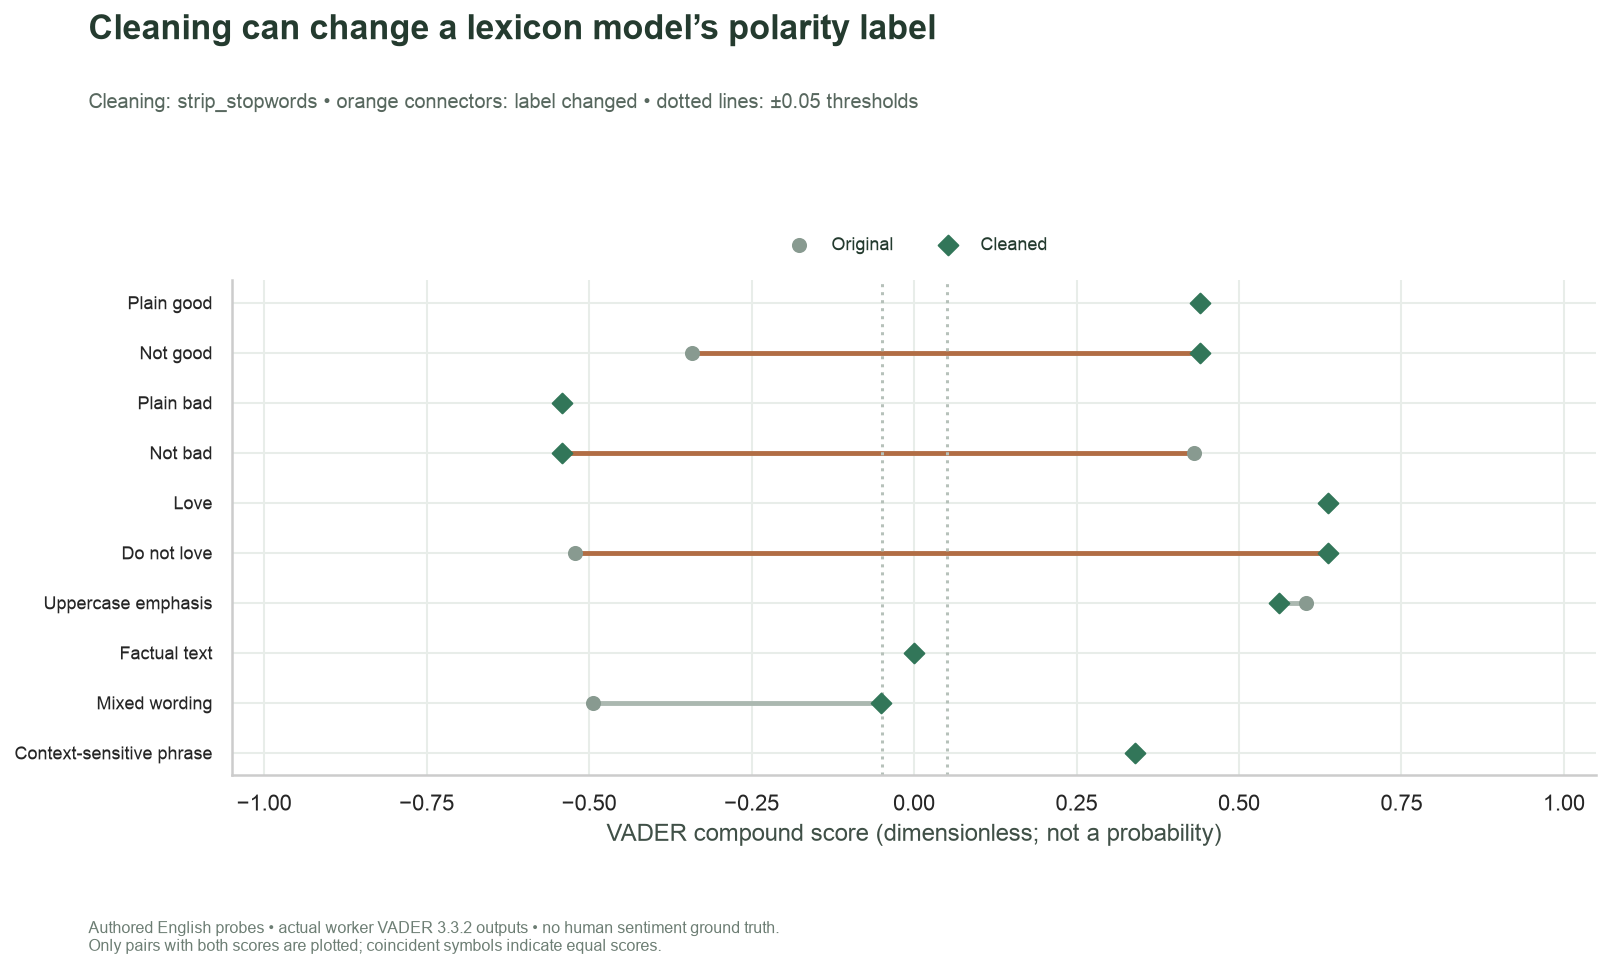

In [9]:
available = comparison_frame[comparison_frame.comparable].copy()
fig, ax = plt.subplots(figsize=(11.5, 6.8))
for i, item in enumerate(available.itertuples()):
    ax.plot(
        [item.original_score, item.cleaned_score],
        [i, i],
        color="#B16D44" if item.label_differs else "#ABB8B0",
        lw=2.4,
    )
ax.scatter(
    available.original_score,
    range(len(available)),
    color="#889A90",
    s=42,
    marker="o",
    label="Original",
    zorder=3,
)
ax.scatter(
    available.cleaned_score,
    range(len(available)),
    color="#327659",
    s=48,
    marker="D",
    label="Cleaned",
    zorder=4,
)
ax.axvline(-0.05, color="#B6C1BA", ls=":")
ax.axvline(0.05, color="#B6C1BA", ls=":")
ax.set_yticks(range(len(available)), available.case_name, fontsize=9)
ax.invert_yaxis()
ax.set(xlabel="VADER compound score (dimensionless; not a probability)", xlim=(-1.05, 1.05))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.12), ncol=2, fontsize=9)
chart(
    fig,
    "Cleaning can change a lexicon model’s polarity label",
    f"Cleaning: {CLEANING_METHOD} • orange connectors: label changed • dotted lines: ±0.05 thresholds",
    "Authored English probes • actual worker VADER 3.3.2 outputs • no human sentiment ground truth.\n"
    "Only pairs with both scores are plotted; coincident symbols indicate equal scores.",
)

## Inspect tokens rather than guessing what vanished

Tokenize both variants with the same English model and retain a variant-specific key. We track the explicit list **not, never, no, n’t** as negation probes; this is not an exhaustive grammar of negation. Other spaCy stopwords, punctuation (`pos = PUNCT`) and remaining tokens are counted separately.

The left join starts from every input variant so text that emits no tokens remains visible as zero tokens. This count is meaningful for a known input; it does not turn an unavailable sentiment score into zero. Token changes can help explain a score shift, but stripping removes multiple features at once and does not isolate one causal mechanism.

In [10]:
%%sql
CREATE TABLE variants AS
SELECT id*2 AS variant_id,id,'Original' AS variant,body AS text_value FROM messages
UNION ALL SELECT id*2+1,id,'Cleaned',cleaned_body FROM cleaned;
CREATE TABLE token_rows AS
SELECT * FROM nlp.main.tokens((SELECT variant_id,text_value FROM variants),
    id:='variant_id',text:='text_value',lang:='en',model:='en_core_web_sm');
CREATE TABLE token_classes AS
SELECT t.*,CASE WHEN lower(token) IN ('not','never','no','n''t') THEN 'Listed negation tokens'
               WHEN pos='PUNCT' THEN 'Punctuation'
               WHEN is_stop THEN 'Other stopwords' ELSE 'Other tokens' END AS token_class
FROM token_rows t;
CREATE TABLE token_summary AS
SELECT v.variant,c.token_class,count(*) AS tokens FROM variants v JOIN token_classes c USING(variant_id)
GROUP BY v.variant,c.token_class;
SELECT v.id,v.variant,count(c.variant_id) AS token_count,
       count(c.variant_id) FILTER(WHERE c.token_class='Listed negation tokens') AS listed_negation_tokens
FROM variants v LEFT JOIN token_classes c USING(variant_id)
GROUP BY v.id,v.variant ORDER BY v.id,v.variant;

Running query in 'DuckDBPyConnection'

26 rows affected.

88 rows affected.

88 rows affected.

5 rows affected.

,id,variant,token_count,listed_negation_tokens
0,1,Cleaned,2,0
1,1,Original,5,0
2,2,Cleaned,2,0
3,2,Original,6,1
4,3,Cleaned,2,0
5,3,Original,5,0
6,4,Cleaned,2,0
7,4,Original,6,1
8,5,Cleaned,3,0
9,5,Original,6,0


In [11]:
%%sql tokens_frame <<
SELECT kinds.token_class,versions.variant,coalesce(t.tokens,0) AS tokens
FROM (VALUES ('Listed negation tokens',1),('Other stopwords',2),('Punctuation',3),('Other tokens',4)) kinds(token_class,display_order)
CROSS JOIN (VALUES ('Original'),('Cleaned')) versions(variant)
LEFT JOIN token_summary t USING(token_class,variant)
ORDER BY kinds.display_order,versions.variant;

Running query in 'DuckDBPyConnection'

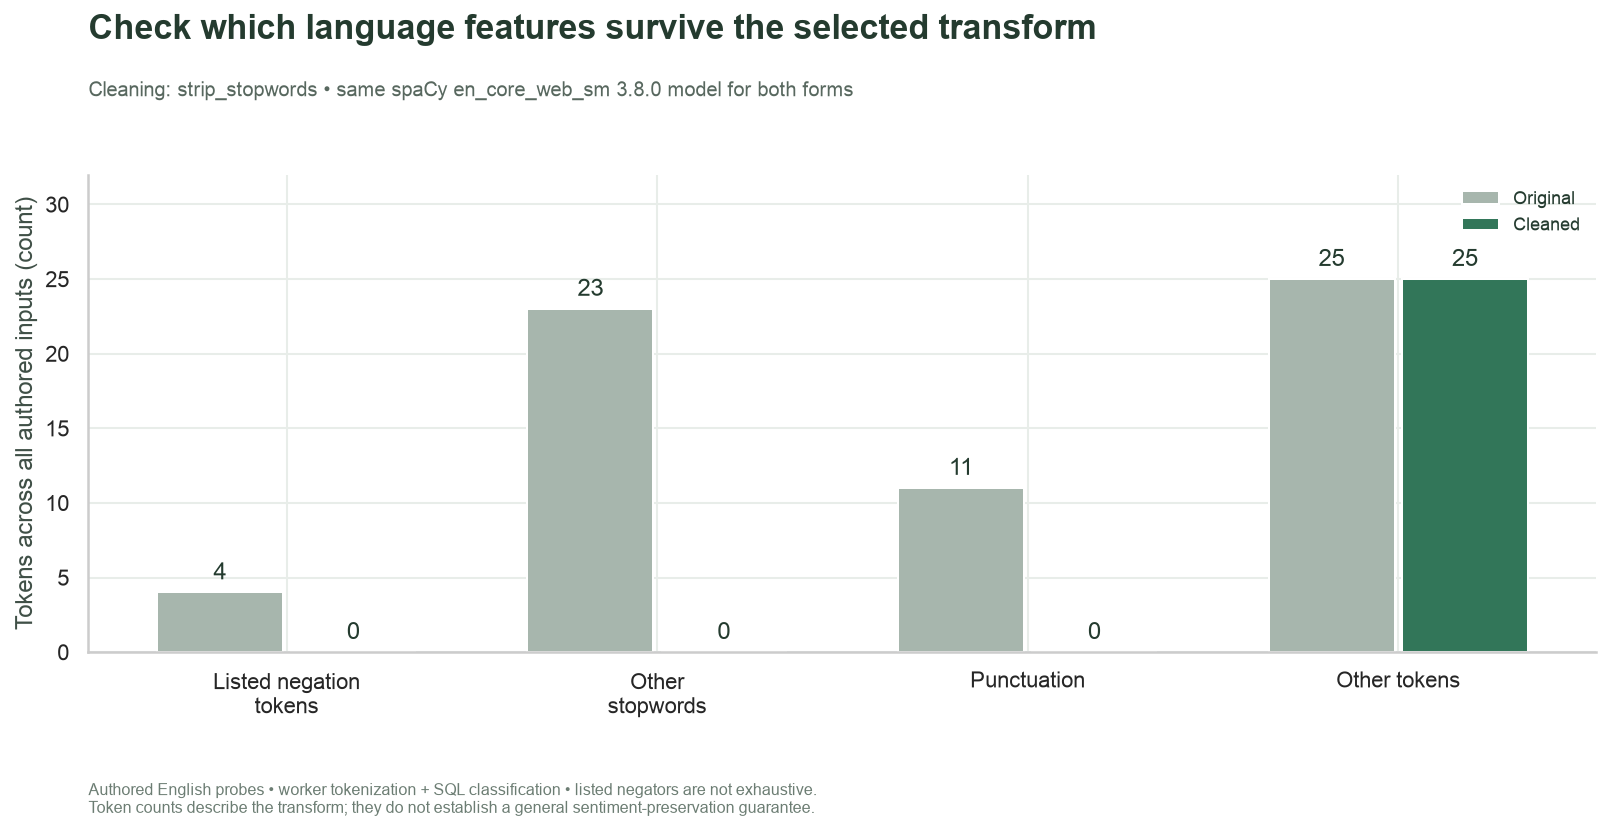

In [12]:
fig, ax = plt.subplots(figsize=(11.5, 5.8))
categories = list(tokens_frame.token_class.unique())
for offset, variant, color in [(-0.18, "Original", "#A7B6AD"), (0.18, "Cleaned", "#327659")]:
    values = [
        int(
            tokens_frame[(tokens_frame.token_class == name) & (tokens_frame.variant == variant)].tokens.iloc[
                0
            ]
        )
        for name in categories
    ]
    bars = ax.bar(
        [i + offset for i in range(len(categories))], values, width=0.34, color=color, label=variant
    )
    ax.bar_label(bars, padding=4)
ax.set_xticks(
    range(len(categories)), ["Listed negation\ntokens", "Other\nstopwords", "Punctuation", "Other tokens"]
)
ax.set_ylabel("Tokens across all authored inputs (count)")
ax.set_ylim(0, max(1, tokens_frame.tokens.max()) * 1.28)
ax.legend(loc="upper right", fontsize=9)
chart(
    fig,
    "Check which language features survive the selected transform",
    f"Cleaning: {CLEANING_METHOD} • same spaCy en_core_web_sm 3.8.0 model for both forms",
    "Authored English probes • worker tokenization + SQL classification "
    "• listed negators are not exhaustive.\n"
    "Token counts describe the transform; they do not establish a general sentiment-preservation guarantee.",
)

## Check scores, labels and key preservation

The checks verify cardinality, score bounds, null-aware threshold agreement, unchanged original text, and token reconciliation. They deliberately do not assert that cleaning must preserve a label or that a sentence has a correct human label. Both policies must pass the same structural checks even when their results differ.

In [13]:
%%sql checks <<
SELECT 'One result per authored input' AS check_name,count(*)=(SELECT count(*) FROM messages) AND count(*)=count(DISTINCT id) AS passed FROM comparison
UNION ALL SELECT 'Original text remains unchanged',bool_and(c.body IS NOT DISTINCT FROM m.body) FROM comparison c JOIN messages m USING(id)
UNION ALL SELECT 'Available scores remain in model bounds',bool_and((original_score IS NULL OR original_score BETWEEN -1 AND 1) AND (cleaned_score IS NULL OR cleaned_score BETWEEN -1 AND 1)) FROM comparison
UNION ALL SELECT 'Original label agrees with returned score',bool_and(original_label IS NOT DISTINCT FROM CASE WHEN original_score IS NULL THEN NULL WHEN original_score>=0.05 THEN 'pos' WHEN original_score<=-0.05 THEN 'neg' ELSE 'neu' END) FROM comparison
UNION ALL SELECT 'Cleaned label agrees with returned score',bool_and(cleaned_label IS NOT DISTINCT FROM CASE WHEN cleaned_score IS NULL THEN NULL WHEN cleaned_score>=0.05 THEN 'pos' WHEN cleaned_score<=-0.05 THEN 'neg' ELSE 'neu' END) FROM comparison
UNION ALL SELECT 'Unavailable pairs have unavailable deltas',bool_and(comparable OR score_change IS NULL) FROM comparison
UNION ALL SELECT 'Null input stays null through cleaning',bool_and(body IS NOT NULL OR cleaned_body IS NULL) FROM cleaned
UNION ALL SELECT 'Each message has two variant keys',count(*)=2*(SELECT count(*) FROM messages) AND count(*)=count(DISTINCT variant_id) FROM variants
UNION ALL SELECT 'Every returned token joins its variant',count(*)=(SELECT count(*) FROM token_rows) FROM token_rows JOIN variants USING(variant_id)
UNION ALL SELECT 'Token classes partition returned tokens',(SELECT sum(tokens) FROM token_summary)=(SELECT count(*) FROM token_rows)
ORDER BY check_name;

Running query in 'DuckDBPyConnection'

In [14]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
prose(
    f"**All {len(checks)} SQL checks passed.** Compare the original and transformed text, score changes "
    "and token categories together. "
    "Passing these invariants establishes a consistent computation, not an accuracy benchmark."
)

,check_name,passed
0,Available scores remain in model bounds,True
1,Cleaned label agrees with returned score,True
2,Each message has two variant keys,True
3,Every returned token joins its variant,True
4,Null input stays null through cleaning,True
5,One result per authored input,True
6,Original label agrees with returned score,True
7,Original text remains unchanged,True
8,Token classes partition returned tokens,True
9,Unavailable pairs have unavailable deltas,True


**All 10 SQL checks passed.** Compare the original and transformed text, score changes and token categories together. Passing these invariants establishes a consistent computation, not an accuracy benchmark.

## Focused experiment: normalize instead of stripping

Change only `CLEANING_METHOD` from **"strip_stopwords"** to **"normalize"**, restart and run all. Predict that explicit negation words and punctuation remain, while case-sensitive emphasis may still change the VADER score. Compare the label-change count, paired-score chart and token categories.

The corpus, model versions and scoring thresholds stay fixed; the chosen transformation changes. This comparison does not establish that either method is universally appropriate. Retaining the original text makes unexpected shifts auditable. Reset to **"strip_stopwords"** for the saved default. The README command saves the experiment separately.

In [15]:
connection.close()
cleanup(previous)
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>